## 训练环境与项目日志初始化

In [1]:
import numpy as np
import json  # 导入json模块
import logging

from data import plot_data, format_dict, make_dirs, TrainingHistory, load_checkpoint, concat
from controller import PIDController, TD3Controller

train_model = False  # 是否训练模型
history: TrainingHistory = None

In [2]:
from datetime import datetime
import os
current_time = datetime.now().strftime("%Y%m%d_%H%M%S")
project_name = input("请输入加载/创建项目的名称 (父目录: .\\savedata) ").strip()# 创建保存模型的基础目录
project_path, ckpt_dir, plt_dir = make_dirs(project_name)
file_path = os.path.join(project_path, f'training_{current_time}.log')
project_path, ckpt_dir, plot_path = make_dirs(project_name)
if train_model:
    logging.basicConfig(filename=file_path, level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # 设置日志格式
logging.info("## 当前时间: %s", datetime.now())
logging.info("项目保存目录: %s", project_path)
logging.info("日志文件: %s", file_path)
logging.info("训练模式: %s", train_model)
print(f"日志文件: {file_path}")

日志文件: savedata\A消融实验\training_20261003_174624.log


In [3]:
import numpy as np
# 计算固有频率
m = 1.0    # 电磁吸振器质量
M = 15  # 待减振对象质量
k_m = 30_000  # 电磁吸振器刚度
k_M = 300_000  # 平台刚度
k_f = 100 # * TD3_PARAMS['action_bound']  # 电—力常数 N/A
# k_E = 0.0  # 作动器反电动势系数
# L = 0.0045  # 线圈的电感
# R_m = 5.0  # 线圈的电阻
c_m = 0.0001 # 1.0  # 电磁吸振器阻尼
c_M = 0.001 # 5.0  # 平台阻尼

f1 = np.sqrt(k_m / m) / (2 * np.pi)  # 电磁吸振器的固有频率
f2 = np.sqrt(k_M / M) / (2 * np.pi)  # 待减振对象的固有频率
print(f"电磁吸振器固有频率: {f1:.2f} Hz")
print(f"待减振对象固有频率: {f2:.2f} Hz")

电磁吸振器固有频率: 27.57 Hz
待减振对象固有频率: 22.51 Hz


## 训练参数

In [4]:
from fx import zero, tolerance_smooth_reward, sin_wave, mls_force
# 理想环境参数
ENV_PARAMS = {
    'Ts': 0.001,  # 环境时间步长
    'T': 2.5,     # 每回合总时间
    'state0': np.array([0.0, 0.0, 0.0, 0.000, 0.0, 0.0]),  # 初始状态
    'obs_indices': [0, 2, 3, 5],  # 观测状态索引
    'x1_limit': 0.03,  # 状态 x1 的限制
    'use_dt_noise': False,  # 是否使用时间步长噪声
    'dt_noise_std': 0.1,  # 时间步长噪声标准差
    'delay_enabled': False,  # 是否启用动作延迟
    'delay_mean_steps': 0,  # 延迟均值步数
    'delay_std_steps': 0,   # 延迟标准差步数
    'include_dt_in_obs': False,  # 是否在观测中包含时间步长
    'include_delay_in_obs': False,  # 是否在观测中包含延迟
    'z_func': zero,  # 状态惩罚函数
    'r_func': tolerance_smooth_reward(1e-3),  # 奖励函数
    'f_func': sin_wave(150, 30),  # 外部激励函数
    # 'f_func': mls_force(amplitude=200, frequency=30, phase=0.3) # 旧为0.3偏移
    # 'f_func': zero,  # 外部激励函数
}

init_type = '定频响应2.5s' # 位移响应/定频响应


# 延迟环境基准参数
DELAY_ENV_PARAMS = ENV_PARAMS.copy()
DELAY_ENV_PARAMS.update({'include_delay_in_obs': True, 'delay_enabled': True, 'delay_mean_steps': 4, 'delay_std_steps': 1})

# delay-mlp环境与控制器参数
DELAY_MLP_ENV_PARAMS = DELAY_ENV_PARAMS.copy()
DELAY_MLP_ENV_PARAMS.update({'include_delay_in_obs': False})
DELAY_MLP_TD3_PARAMS = {
    # 创建神经网络的参数
    'arch': 'mlp',  # 网络架构类型
    'norm': False,      # 是否使用归一化
    'simple_nn': False,  # 是否使用简单神经网络
    'state_dim': len(DELAY_MLP_ENV_PARAMS['obs_indices']) + int(DELAY_MLP_ENV_PARAMS['include_dt_in_obs']) + int(DELAY_MLP_ENV_PARAMS['include_delay_in_obs']),  # 状态维度
    'action_dim': 1,  # 动作维度
    'action_bound': 5,  # 动作边界
    'gru_hidden': 64,  # GRU 隐藏层大小
    'gru_layers': 1,   # GRU 层数
    'hidden_dim': 64,  # 全连接层隐藏维度
    'seq_len': 36,     # 预测前序列长度
    'fc_seq_len': 4,   # 预测器预测序列长度
    # 优化器参数
    'actor_lr': 3e-06,  # Actor 学习率
    'critic_lr': 1e-05,  # Critic 学习率
    'clip_grad': 1.0,  # 梯度裁剪值
    'tau': 0.002,      # 软更新参数 SEQ取0.001
    # TD3 算法参数
    'gamma': 0.99,     # 折扣因子
    'policy_noise': 0.2,  # 策略噪声标准差
    'noise_clip': 0.5,   # 噪声裁剪值
    'policy_freq': 3,   # 策略延迟频率 
}

# delay-grua基准环境与控制器参数
DELAY_GRUA_ENV_PARAMS = DELAY_ENV_PARAMS.copy()
DELAY_GRUA_TD3_PARAMS = {
    # 创建神经网络的参数
    'arch': 'seq',  # 网络架构类型
    'norm': False,      # 是否使用归一化
    'simple_nn': False,  # 是否使用简单神经网络
    'state_dim': len(DELAY_GRUA_ENV_PARAMS['obs_indices']) + int(DELAY_GRUA_ENV_PARAMS['include_dt_in_obs']) + int(DELAY_GRUA_ENV_PARAMS['include_delay_in_obs']),  # 状态维度
    'action_dim': 1,  # 动作维度
    'action_bound': 5,  # 动作边界
    'gru_hidden': 64,  # GRU 隐藏层大小
    'gru_layers': 1,   # GRU 层数
    'hidden_dim': 128,  # 全连接层隐藏维度
    'seq_len': 36,     # 预测前序列长度
    'fc_seq_len': 4,   # 预测器预测序列长度
    # 优化器参数
    'actor_lr': 5e-06,  # Actor 学习率
    'critic_lr': 1e-05,  # Critic 学习率
    'clip_grad': 1.0,  # 梯度裁剪值
    'tau': 0.001,      # 软更新参数 SEQ取0.001
    # TD3 算法参数
    'gamma': 0.99,     # 折扣因子
    'policy_noise': 0.2,  # 策略噪声标准差
    'noise_clip': 0.5,   # 噪声裁剪值
    'policy_freq': 3,   # 策略延迟频率 
    'freeze_attention': False, # 是否冻结注意力机制的参数
}

# Delay-GRUA不观测延迟环境与控制器参数
DELAY_NOTIME_GRUA_ENV_PARAMS = DELAY_ENV_PARAMS.copy()
DELAY_NOTIME_GRUA_ENV_PARAMS.update({'include_delay_in_obs': False})
DELAY_NOTIME_GRUA_TD3_PARAMS = DELAY_GRUA_TD3_PARAMS.copy()
DELAY_NOTIME_GRUA_TD3_PARAMS.update({'state_dim': len(DELAY_NOTIME_GRUA_ENV_PARAMS['obs_indices']) + int(DELAY_NOTIME_GRUA_ENV_PARAMS['include_dt_in_obs']) + int(DELAY_NOTIME_GRUA_ENV_PARAMS['include_delay_in_obs'])})

# Delay-GRUA固定注意力延迟环境与控制器参数
DELAY_GRU_FA_ENV_PARAMS = DELAY_ENV_PARAMS.copy()
DELAY_GRU_FA_TD3_PARAMS = DELAY_GRUA_TD3_PARAMS.copy()
DELAY_GRU_FA_TD3_PARAMS.update({'freeze_attention': True})

In [5]:
model_paths= [
            #   "GRUA-TD3\savedata\A结题报告对比\S8_0317下午无延迟_0318_122157_ep465ckpt.pth",
            #   "GRUA-TD3/savedata/A结题报告对比/S8_0321下午-1延迟_0408_160251_ep60ckpt.pth",
            #   "GRUA-TD3\savedata\A结题报告对比\S8_0323下午-2延迟_0323_155619_ep120ckpt.pth",
            #   "GRUA-TD3\savedata\A结题报告对比\S8_0323下午-3延迟_0323_173858_ep100ckpt.pth",
            #   "GRUA-TD3/savedata/A结题报告对比/S8_0323下午-4延迟_0323_183711_ep60ckpt.pth,",
            #   "GRUA-TD3\savedata\A结题报告对比\S8_0324下午-4-1延迟_0324_153934_ep100ckpt.pth",
            #   "GRUA-TD3/savedata/A结题报告对比/S10_0327中午MLP无延迟_0328_002325_ep900ckpt.pth",
            #   "GRUA-TD3\savedata\A结题报告对比\S10_0328中午MLP-1延迟_0329_194306_ep500ckpt.pth",
            #   "GRUA-TD3/savedata/A结题报告对比/S10_0331上午MLP-2延迟_0331_132010_ep620ckpt.pth",
            #   "GRUA-TD3\savedata\A结题报告对比\S10_0331下午MLP-3延迟_0408_151329_ep795ckpt.pth",
            #   "GRUA-TD3\savedata\A结题报告对比\S10_0401下午MLP-3-1延迟_0401_191717_ep800ckpt.pth",
            #   "GRUA-TD3\savedata\A结题报告对比\S11_0407下午MLP无延迟_0408_123238_ep460ckpt.pth",
            "E:/100_Study/130_SubjectLearn/1310_DySysIdCtrl/电磁式阻尼器深度强化学习/GRUA-TD3/savedata/A消融实验/T5-3-MLPTD3-S10_0401下午MLP-3-1延迟_0401_191717_ep800ckpt.pth",
            "E:/100_Study/130_SubjectLearn/1310_DySysIdCtrl/电磁式阻尼器深度强化学习/GRUA-TD3/savedata/A消融实验/T5-1-GRUA不观测延迟-0929_160522_ep70ckpt.pth",
            "E:/100_Study/130_SubjectLearn/1310_DySysIdCtrl/电磁式阻尼器深度强化学习/GRUA-TD3/savedata/A消融实验/T5-2-GRUA-固定Att-1001_124458_ep150ckpt.pth",
            "E:/100_Study/130_SubjectLearn/1310_DySysIdCtrl/电磁式阻尼器深度强化学习/GRUA-TD3/savedata/A消融实验/T4-2-GRUA基准-0928_204140_ep200ckpt.pth",
              ]

In [6]:
# 创建控制器与对应的环境
# 创建mlp基准控制器

MLP_TD3_Controller = TD3Controller(**DELAY_MLP_TD3_PARAMS)
payload = load_checkpoint(model_paths[0])
MLP_TD3_Controller.load_state(payload["agent"])

# 创建gura-notime控制器
GRUA_NoTime_TD3_Controller = TD3Controller(**DELAY_NOTIME_GRUA_TD3_PARAMS)
payload = load_checkpoint(model_paths[1])
GRUA_NoTime_TD3_Controller.load_state(payload["agent"])

# 创建gru-fixed-attention控制器
GRU_FA_TD3_Controller = TD3Controller(**DELAY_GRU_FA_TD3_PARAMS)
payload = load_checkpoint(model_paths[2])
GRU_FA_TD3_Controller.load_state(payload["agent"])

# 创建grua基准控制器
GRUA_TD3_Controller = TD3Controller(**DELAY_GRUA_TD3_PARAMS)
payload = load_checkpoint(model_paths[3])
GRUA_TD3_Controller.load_state(payload["agent"])

e:\100_Study\130_SubjectLearn\1310_DySysIdCtrl\.venv\lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.1 and num_layers=1
  warnings.warn(


In [7]:
# 创建环境
from env import build_env
delay_env = build_env(DELAY_ENV_PARAMS)
delay_mlp_env = build_env(DELAY_MLP_ENV_PARAMS)
delay_notime_grua_env = build_env(DELAY_NOTIME_GRUA_ENV_PARAMS)
delay_gru_fa_env = build_env(DELAY_GRU_FA_ENV_PARAMS)
delay_grua_env = build_env(DELAY_GRUA_ENV_PARAMS)

# 无控制
delay_nc_recorder = delay_env.run_episode_with_controller(controller=None, state0=ENV_PARAMS['state0'], z_func=ENV_PARAMS['z_func'], f_func=ENV_PARAMS['f_func'])
delay_nc_x_values=delay_nc_recorder.as_numpy(keys='time_history').reshape(-1, 1)
delay_nc_y_values=delay_nc_recorder.as_numpy(keys='state_history')[:,[0,1,2,3,4,5]]

# delay-mlp环境控制
delay_mlp_recorder = delay_mlp_env.run_episode_with_controller(controller=MLP_TD3_Controller, state0=DELAY_MLP_ENV_PARAMS['state0'], z_func=DELAY_MLP_ENV_PARAMS['z_func'], f_func=DELAY_MLP_ENV_PARAMS['f_func'])
delay_mlp_x_values=delay_mlp_recorder.as_numpy(keys='time_history').reshape(-1, 1)
delay_mlp_y_values=delay_mlp_recorder.as_numpy(keys='state_history')[:,[0,1,2,3,4,5]]

# delay-grua-notime环境控制
delay_notime_grua_recorder = delay_notime_grua_env.run_episode_with_controller(controller=GRUA_NoTime_TD3_Controller, state0=DELAY_NOTIME_GRUA_ENV_PARAMS['state0'], z_func=DELAY_NOTIME_GRUA_ENV_PARAMS['z_func'], f_func=DELAY_NOTIME_GRUA_ENV_PARAMS['f_func'])
delay_notime_grua_x_values=delay_notime_grua_recorder.as_numpy(keys='time_history').reshape(-1, 1)
delay_notime_grua_y_values=delay_notime_grua_recorder.as_numpy(keys='state_history')[:,[0,1,2,3,4,5]]

# delay-gru-fixed-attention环境控制
delay_gru_fa_recorder = delay_gru_fa_env.run_episode_with_controller(controller=GRU_FA_TD3_Controller, state0=DELAY_GRU_FA_ENV_PARAMS['state0'], z_func=DELAY_GRU_FA_ENV_PARAMS['z_func'], f_func=DELAY_GRU_FA_ENV_PARAMS['f_func'])
delay_gru_fa_x_values=delay_gru_fa_recorder.as_numpy(keys='time_history').reshape(-1, 1)
delay_gru_fa_y_values=delay_gru_fa_recorder.as_numpy(keys='state_history')[:,[0,1,2,3,4,5]]

# delay-grua环境控制
delay_grua_recorder = delay_grua_env.run_episode_with_controller(controller=GRUA_TD3_Controller, state0=DELAY_GRUA_ENV_PARAMS['state0'], z_func=DELAY_GRUA_ENV_PARAMS['z_func'], f_func=DELAY_GRUA_ENV_PARAMS['f_func'])
delay_grua_x_values=delay_grua_recorder.as_numpy(keys='time_history').reshape(-1, 1)
delay_grua_y_values=delay_grua_recorder.as_numpy(keys='state_history')[:,[0,1,2,3,4,5]]

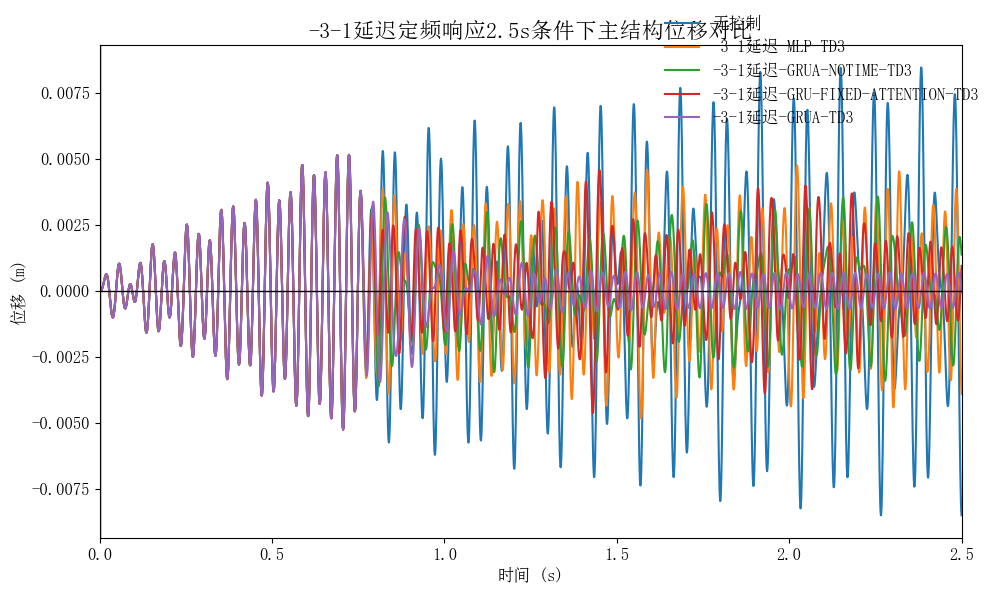

In [8]:
# 对比-3-1延迟条件下mlp-td3、grua-notime-td3、gru-fixed-attention-td3和grua-td3控制的位移响应
x_values = concat(delay_nc_x_values, delay_mlp_x_values, delay_notime_grua_x_values, delay_gru_fa_x_values, delay_grua_x_values, axis=0, concat_axis=1) # 将有控制器和无控制器的时间数据合并
y_values = concat(delay_nc_y_values[:, [3]], delay_mlp_y_values[:, [3]], delay_notime_grua_y_values[:, [3]], delay_gru_fa_y_values[:, [3]], delay_grua_y_values[:, [3]], axis=0, concat_axis=1) # 将有控制器和无控制器的主结构位移数据合并
plot_data(figsize=(10, 6), x_values=x_values, y_values=y_values,
            total_legend=['无控制','-3-1延迟-MLP-TD3', '-3-1延迟-GRUA-NOTIME-TD3', '-3-1延迟-GRU-FIXED-ATTENTION-TD3', '-3-1延迟-GRUA-TD3'], legend_loc='upper right',
            sub_group=[(0,1,2,3,4),], xlabel='时间 (s)', ylabel='位移 (m)',
            subplot_titles=[f'-3-1延迟{init_type}条件下主结构位移对比'], xlim=(0,ENV_PARAMS['T']),
            plot_title=f'', save_path=plot_path, show=True,
            totalsize=12, title_fontsize=16, label_fontsize=12, legend_fontsize=12)

In [9]:
# 存储数据到CSV文件
data_path = os.path.join(project_path, f"{init_type}_data")
os.makedirs(data_path, exist_ok=True)
delay_nc_recorder.save_csv(os.path.join(data_path, "delay_nc_recorder.csv"))
delay_mlp_recorder.save_csv(os.path.join(data_path, "delay_mlp_recorder.csv"))
delay_notime_grua_recorder.save_csv(os.path.join(data_path, "delay_notime_grua_recorder.csv"))
delay_gru_fa_recorder.save_csv(os.path.join(data_path, "delay_gru_fa_recorder.csv"))
delay_grua_recorder.save_csv(os.path.join(data_path, "delay_grua_recorder.csv"))